In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/upi_synthetic.csv")
print(df.shape)
print(df["is_fraud"].value_counts())
df.head()

(100000, 8)
is_fraud
0    98527
1     1473
Name: count, dtype: int64


,amount,hour,account_age_days,txn_count_24h,new_receiver,device_changed,location_mismatch,is_fraud
0,581.53,8,1290,2,0,0,0,0
1,115.82,11,465,3,1,0,0,0
2,992.81,6,272,3,0,0,0,0
3,1247.23,23,623,1,0,0,0,0
4,38.81,10,1169,4,1,0,0,0


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("is_fraud", axis=1)
y = df["is_fraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

num_cols = ["amount", "account_age_days", "txn_count_24h"]
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print(X_train.shape, X_test.shape)
print("Train fraud:", y_train.sum(), "| Test fraud:", y_test.sum())

(80000, 7) (20000, 7)
Train fraud: 1178 | Test fraud: 295


In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

ratio = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=100, max_depth=10,
                                           class_weight="balanced_subsample",
                                           n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1,
                             scale_pos_weight=ratio, eval_metric="aucpr",
                             random_state=42),
}

for name, model in models.items():
    print("Training", name, "...")
    model.fit(X_train, y_train)
print("Done!")

Training LogisticRegression ...
Training RandomForest ...
Training XGBoost ...
Done!


In [4]:
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score

rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "PR-AUC": average_precision_score(y_test, proba),
    })

results = pd.DataFrame(rows).round(3)
results.to_csv("../reports/upi_model_results.csv", index=False)
results

,Model,Precision,Recall,F1,PR-AUC
0,LogisticRegression,0.045,0.742,0.085,0.171
1,RandomForest,0.062,0.481,0.109,0.066
2,XGBoost,0.050,0.634,0.093,0.112


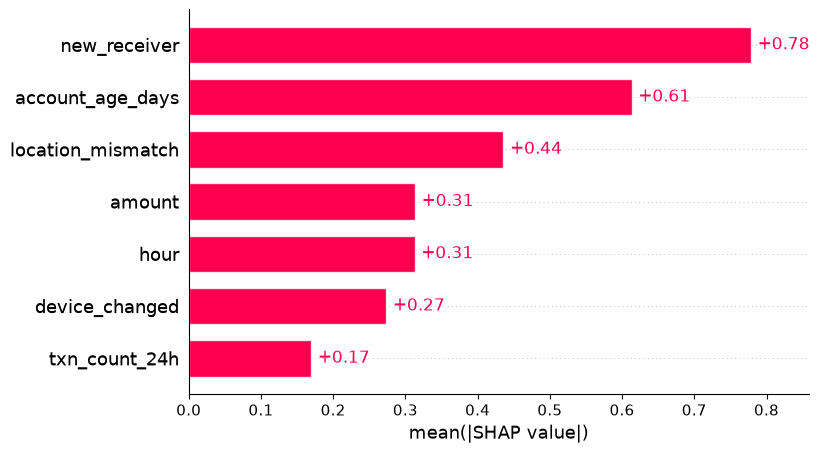

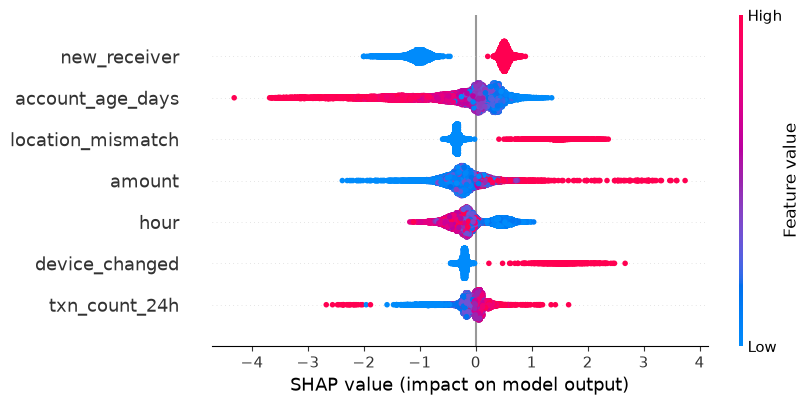

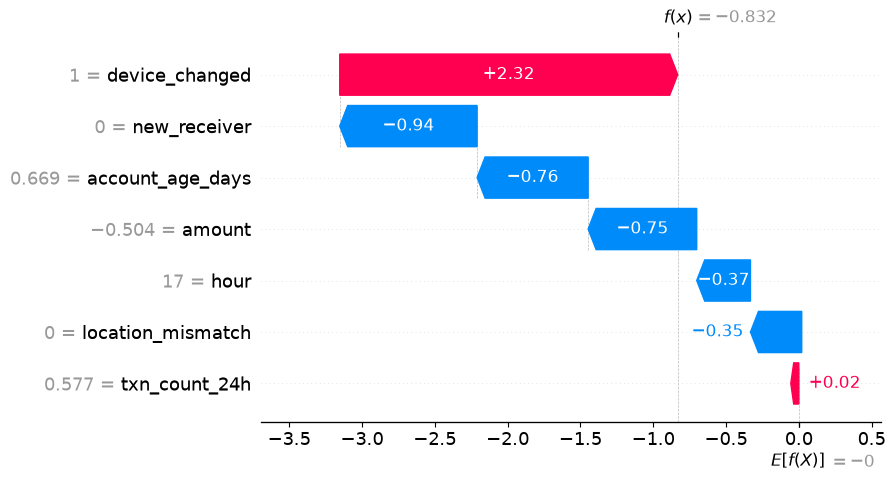

In [5]:
import shap

xgb_model = models["XGBoost"]
explainer = shap.TreeExplainer(xgb_model)
sv = explainer(X_test)

plt.figure()
shap.plots.bar(sv, show=False)
plt.savefig("../reports/figures/upi_shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure()
shap.plots.beeswarm(sv, show=False)
plt.savefig("../reports/figures/upi_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

pos = np.where(y_test.values == 1)[0][0]
plt.figure()
shap.plots.waterfall(sv[pos], show=False)
plt.savefig("../reports/figures/upi_shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
import joblib
joblib.dump(xgb_model, "../models/xgb_upi.pkl")
joblib.dump(scaler, "../models/scaler_upi.pkl")

['../models/scaler_upi.pkl']